# 01 · Exploratory data analysis — FD001 then FD002

**Goal.** Understand what the raw C-MAPSS files contain before any modelling: how long engines live,
which sensors carry a degradation signal, which are constant, and how the operating conditions of
FD002 hide that signal. Every figure has a one-line interpretation underneath and is saved to `figures/`.

Conventions used everywhere: the RUL label is `min(max_cycle − cycle, RUL_CAP)` with `RUL_CAP = 125`
(`src/config.py`), and every random choice takes the seed `SEED = 0`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import SEED, RUL_CAP, SENSOR_COLS, SETTING_COLS, KNOWN_CONSTANT_SENSORS, find_data_dir
from src.load import load_subset, summary_table
from src.features import add_rul, sensor_variance_table, FeaturePipeline, CONSTANT_STD_TOL
from src.plots import (save, plot_lifetime_hist, plot_sensor_traces, plot_rul_correlation,
                       plot_settings_scatter, plot_before_after_regime)

pd.set_option("display.width", 160)
pd.set_option("display.precision", 3)
print("raw data folder:", find_data_dir())

raw data folder: /Users/anaangelescu/Desktop/Courses/TFG BIDA/data/6. Turbofan Engine Degradation Simulation Data Set-CMAPSSData


## 0. Step 1 check — load and integrity

`load_subset` asserts the row / engine counts of every file (`python -m src.load --check` does the same
for all four subsets from the command line).

In [2]:
summary_table(["FD001", "FD002"]).T

subset,FD001,FD002
train_rows,20631.0,53759.0
train_units,100.0,260.0
test_rows,13096.0,33991.0
test_units,100.0,259.0
life_min,128.0,128.0
life_median,199.0,199.0
life_max,362.0,378.0
test_len_min,31.0,21.0
test_len_max,303.0,367.0
rul_min,7.0,6.0


FD001 and FD002 share the same lifetime range (128–362 / 128–378 cycles, median 199), but FD002 has
2.6× more engines and its settings take six distinct values instead of one. Official test histories
are truncated anywhere between 21 and 367 cycles, and the true RUL after the last cycle ranges from
6 to 194 — i.e. some test engines are still far from failure.

## 1. FD001 — one operating condition, one fault mode

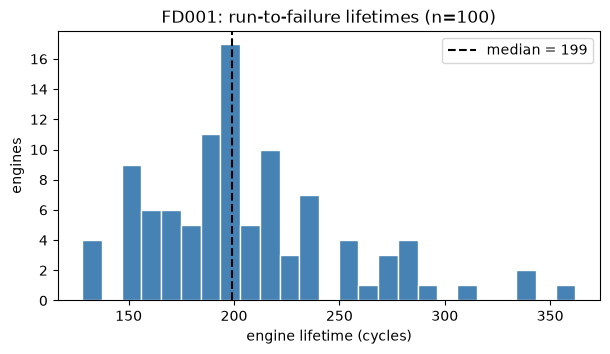

In [3]:
train, test, rul = load_subset("FD001")
train = add_rul(train)  # capped label, needed for the correlation section
fig = plot_lifetime_hist(train, "FD001")
save(fig, "eda_fd001_lifetimes.png")

**Interpretation.** Lifetimes are right-skewed, 128–362 cycles with a median of 199: engine age alone
is a poor predictor of remaining life, which is why the sensors are needed — and why the label is
capped at 125 (during the first ~100 cycles nothing in the sensors distinguishes "200 left" from "100 left").

random engines: [27, 31, 51, 62, 82]


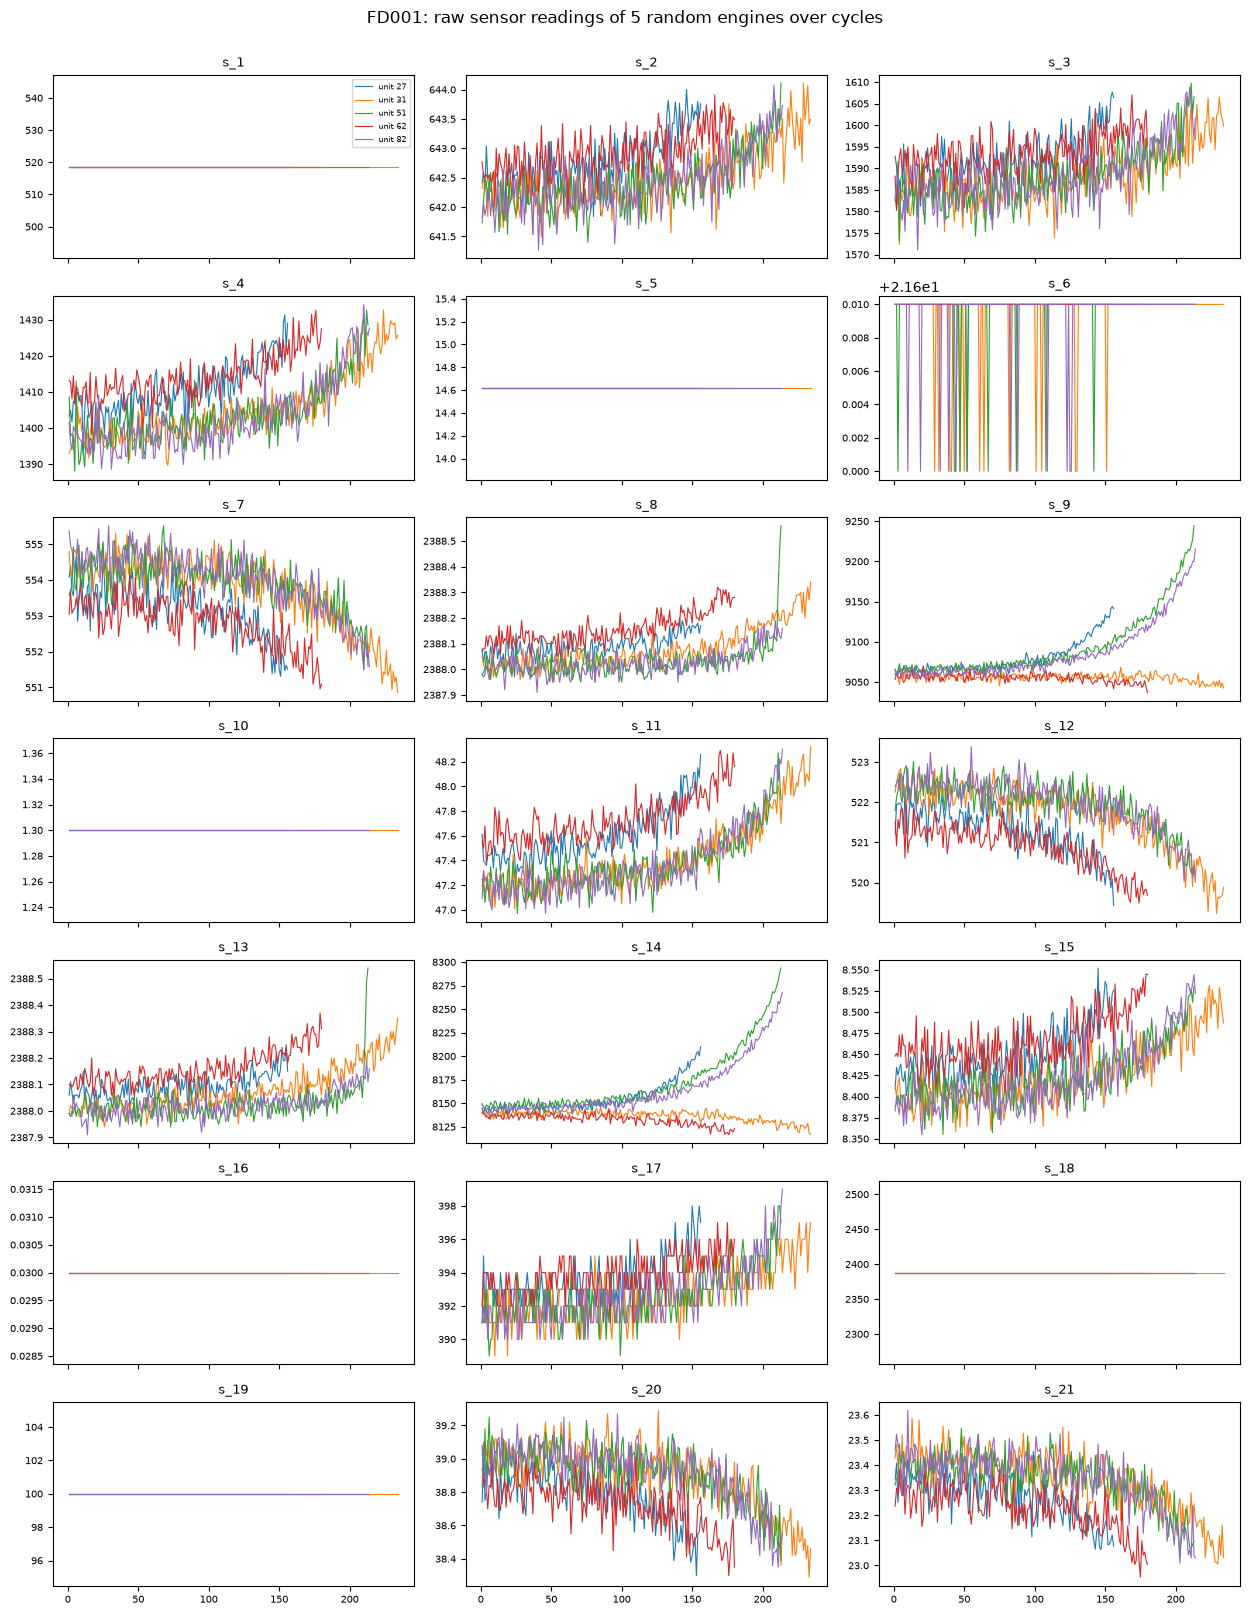

In [4]:
rng = np.random.default_rng(SEED)
units = np.sort(rng.choice(train["unit"].unique(), size=5, replace=False))
print("random engines:", units.tolist())
fig = plot_sensor_traces(train, units, "FD001")
save(fig, "eda_fd001_sensor_traces.png")

**Interpretation.** Seven sensors are flat lines (s_1, s_5, s_10, s_16, s_18, s_19 exactly constant,
s_6 toggling between two quantisation levels); the remaining 14 drift in the last ~100 cycles of each
engine — ten rise towards failure (s_2, s_3, s_4, s_8, s_9, s_11, s_13, s_14, s_15, s_17) and four
fall (s_7, s_12, s_20, s_21). The drift is small compared with the cycle-to-cycle noise, which
motivates the rolling-window features of step 3. Note s_9 and s_14: they rise steeply for three of
these five engines and drift down for the other two, so their average trend is the weakest of the
fourteen (see the correlation table below).

In [5]:
var_table = sensor_variance_table(train)
constant = var_table.index[var_table["constant"]].tolist()
print(f"flagged as constant (std < {CONSTANT_STD_TOL}):", constant)
assert constant == KNOWN_CONSTANT_SENSORS
var_table.round(4)

flagged as constant (std < 0.01): ['s_1', 's_5', 's_6', 's_10', 's_16', 's_18', 's_19']


,mean,std,var,n_unique,constant
s_1,518.670,0.000,0.000,1,True
s_2,642.681,0.500,0.250,310,False
s_3,1590.523,6.131,37.591,3012,False
s_4,1408.934,9.001,81.011,4051,False
s_5,14.620,0.000,0.000,1,True
s_6,21.610,0.001,0.000,2,True
s_7,553.368,0.885,0.783,513,False
s_8,2388.097,0.071,0.005,53,False
s_9,9065.243,22.083,487.654,6403,False
s_10,1.300,0.000,0.000,1,True


**Interpretation.** The variance criterion flags exactly the seven sensors reported in the literature
(s_1, s_5, s_6, s_10, s_16, s_18, s_19); `n_unique` confirms they take 1–2 values. They are dropped
in step 3 because a constant feature cannot carry information about RUL.

,RUL capped at 125,RUL uncapped
s_11,-0.775,-0.696
s_4,-0.757,-0.679
s_12,0.749,0.672
s_7,0.733,0.657
s_15,-0.721,-0.643
s_21,0.707,0.636
s_20,0.705,0.629
s_17,-0.681,-0.606


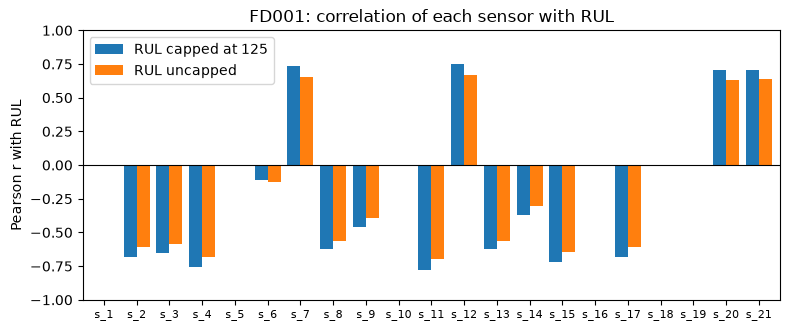

In [6]:
rul_uncapped = train.groupby("unit")["cycle"].transform("max") - train["cycle"]
# Constant sensors have zero variance -> undefined correlation; numpy would warn on the 0/0 division.
with np.errstate(divide="ignore", invalid="ignore"):
    corr = pd.DataFrame({
        f"RUL capped at {RUL_CAP}": train[SENSOR_COLS].corrwith(train["rul"]),
        "RUL uncapped": train[SENSOR_COLS].corrwith(rul_uncapped),
    })
fig = plot_rul_correlation(corr, "FD001")
save(fig, "eda_fd001_rul_correlation.png")
ranked = corr.dropna().reindex(corr.iloc[:, 0].abs().sort_values(ascending=False).index).dropna()
ranked.head(8)

**Interpretation.** Every informative sensor correlates more strongly with the capped label than with
the raw countdown (|r| up to 0.78 vs 0.70): sensors are flat early in life, exactly where the uncapped
RUL is large but uninformative — capping the label removes a stretch of the target that nothing in the
data explains. The strongest signals are s_11, s_4, s_12, s_7, s_15 and s_21 (|r| ≈ 0.71–0.78); the
weakest of the retained sensors are s_14 (−0.37) and s_9 (−0.46), the two whose direction differs
between engines. The sign tells whether a sensor rises (negative r) or falls (positive r) towards
failure. Constant sensors have undefined correlation and are absent from the plot.

## 2. FD002 — six operating conditions, one fault mode

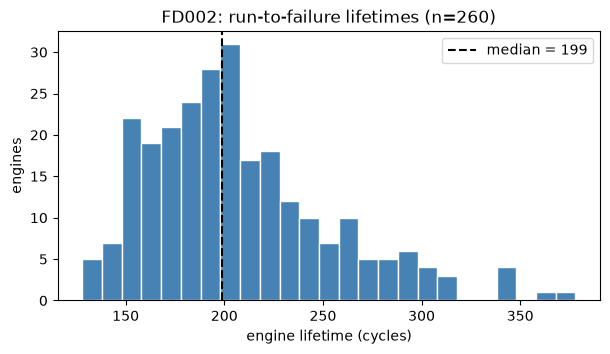

In [7]:
train2, test2, rul2 = load_subset("FD002")
train2 = add_rul(train2)
fig = plot_lifetime_hist(train2, "FD002")
save(fig, "eda_fd002_lifetimes.png")

**Interpretation.** The lifetime distribution of FD002 is practically the same as FD001 (128–378,
median 199): the difficulty of FD002 is not in how long engines live but in how their readings are
recorded.

random engines: [70, 81, 132, 164, 218]


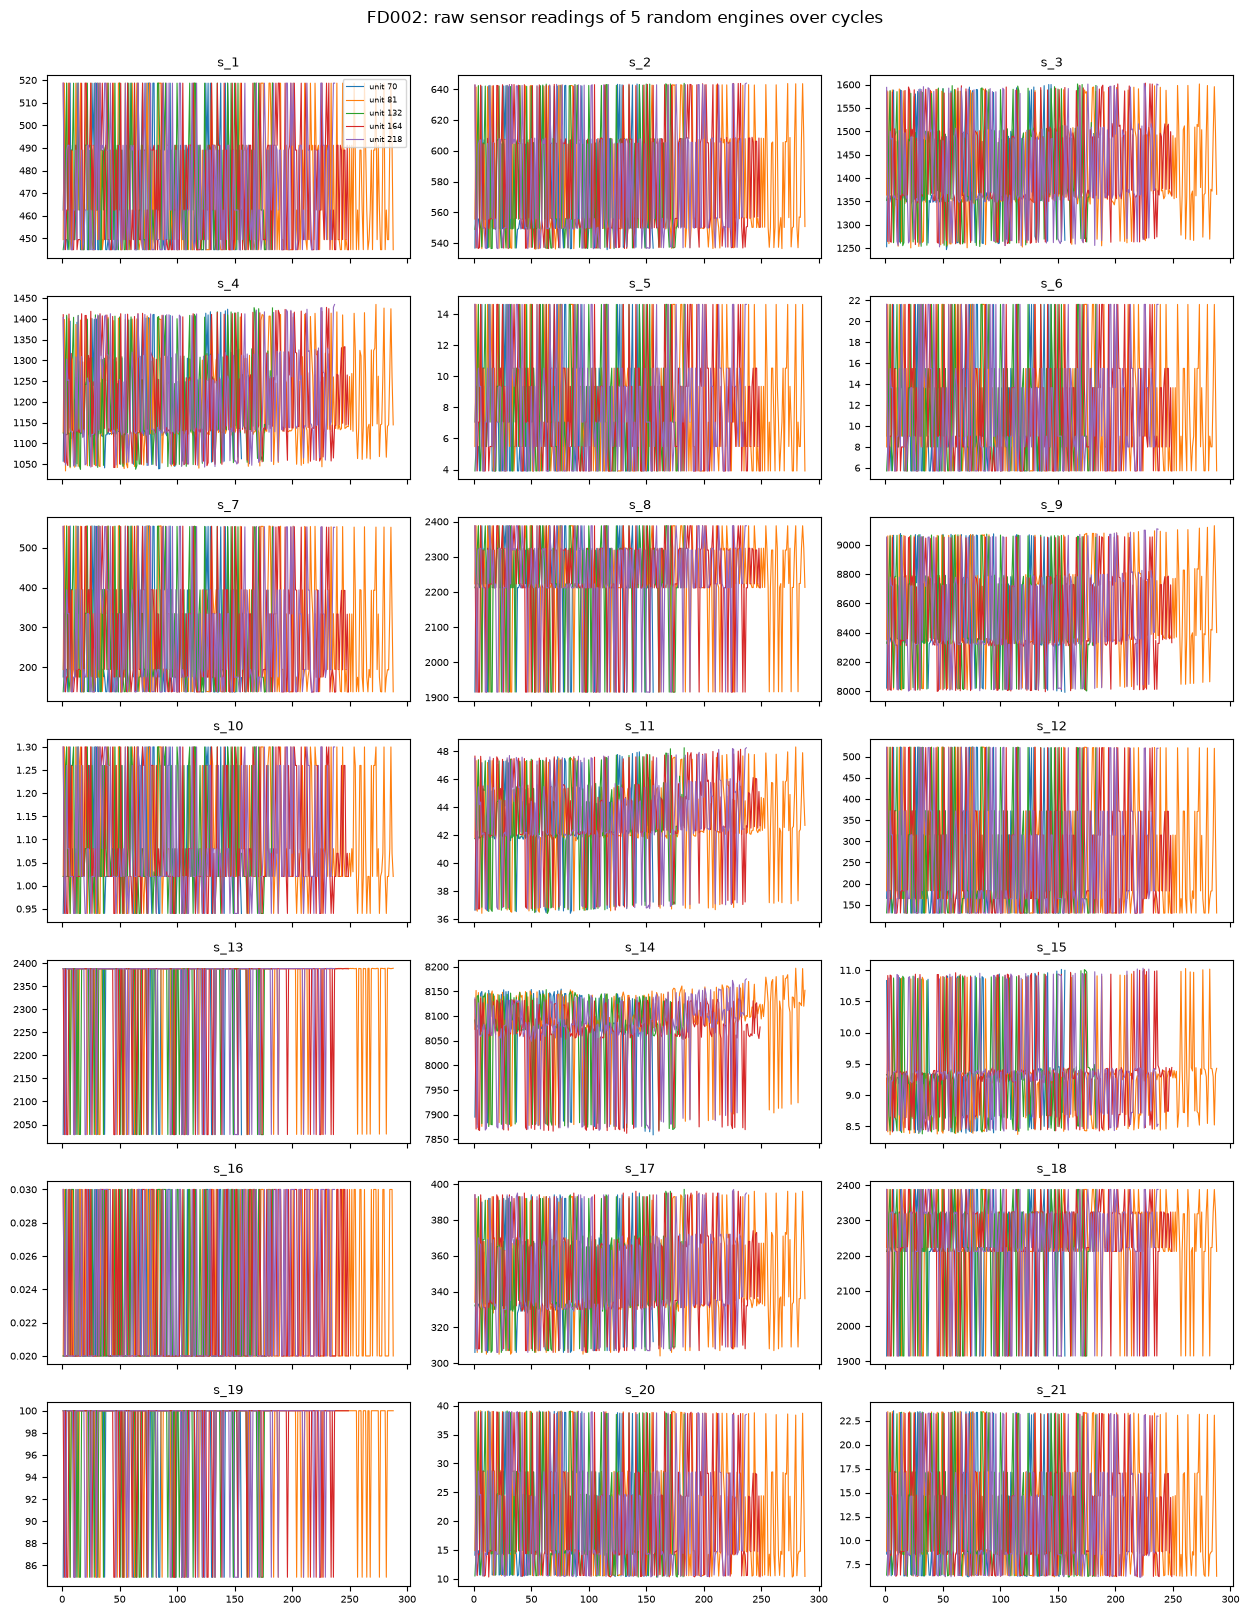

In [8]:
units2 = np.sort(np.random.default_rng(SEED).choice(train2["unit"].unique(), size=5, replace=False))
print("random engines:", units2.tolist())
fig = plot_sensor_traces(train2, units2, "FD002")
save(fig, "eda_fd002_sensor_traces.png")

**Interpretation.** The raw traces jump between six levels from one cycle to the next: the operating
condition, not the health of the engine, dominates every sensor, and no degradation trend is visible
by eye. Sensors that were constant in FD001 now change with the condition as well.

,setting_1,setting_2,setting_3,rows
regime,,,,
0,42.0,0.84,100.0,13458
1,0.0,0.00,100.0,8044
2,25.0,0.62,60.0,8002
3,20.0,0.70,100.0,8122
4,10.0,0.25,100.0,8096
5,35.0,0.84,100.0,8037


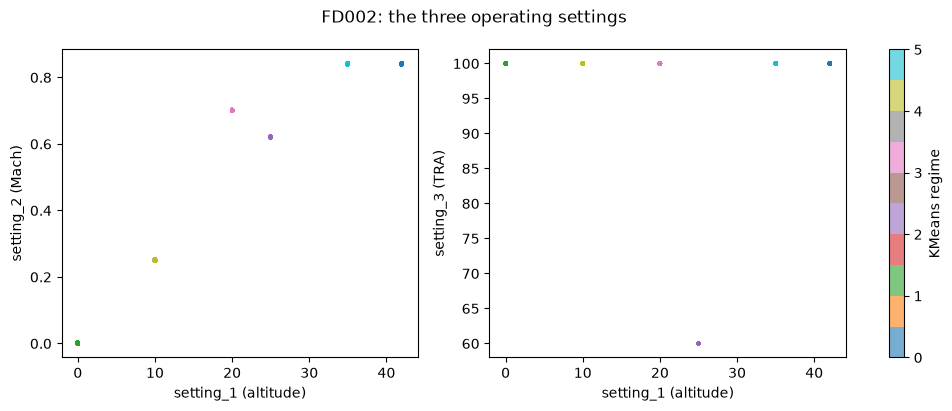

In [9]:
# EDA only: the regime clustering is fitted on all training engines here; the experiments refit it
# on their 70 % training engines (src/experiment.py).
pipe2 = FeaturePipeline("FD002", seed=SEED).fit(train2)
regime = pipe2.assign_regime(train2)
fig = plot_settings_scatter(train2, "FD002", regime)
save(fig, "eda_fd002_settings_clusters.png")
centres = train2.groupby(regime.to_numpy())[SETTING_COLS].mean().round(2)
centres["rows"] = regime.value_counts().sort_index()
centres.index.name = "regime"
centres

**Interpretation.** The three settings form six tight, well-separated clusters — the six documented
operating conditions (altitude ≈ 0/10/20/25/35/42 kft, Mach ≈ 0/0.25/0.7/0.62/0.84/0.84, throttle
100 or 60) — with roughly balanced row counts, so KMeans with k = 6 and a fixed seed recovers them
exactly and the regime id is a reliable key for per-regime normalisation.

In [10]:
var2 = sensor_variance_table(train2)
within = train2[SENSOR_COLS].groupby(regime.to_numpy()).std().max().rename("max std within regime")
var2 = var2.join(within)
var2["constant_within_regime"] = var2["max std within regime"] < CONSTANT_STD_TOL
print("globally constant      :", var2.index[var2["constant"]].tolist())
print("constant within regime :", var2.index[var2["constant_within_regime"]].tolist())
var2.round(4)

globally constant      : ['s_16']
constant within regime : ['s_1', 's_5', 's_6', 's_10', 's_16', 's_18', 's_19']


,mean,std,var,n_unique,constant,max std within regime,constant_within_regime
s_1,472.910,26.390,696.417,6,False,0.000,True
s_2,579.672,37.289,1390.499,1590,False,0.496,False
s_3,1419.971,105.946,11224.627,12305,False,6.022,False
s_4,1205.442,119.123,14190.391,15411,False,8.937,False
s_5,8.032,3.614,13.060,6,False,0.000,True
s_6,11.601,5.432,29.505,14,False,0.005,True
s_7,282.607,146.005,21317.549,2067,False,0.868,False
s_8,2228.879,145.210,21085.891,897,False,0.300,False
s_9,8525.201,335.812,112769.708,22434,False,19.213,False
s_10,1.095,0.128,0.016,9,False,0.004,True


**Interpretation.** Judged globally, no FD002 sensor looks constant because all of them shift with
the operating condition; judged inside each regime the same seven sensors as in FD001 are flat.
This is why `FeaturePipeline` measures variance per regime before deciding what to drop.

,raw sensors,z-scored within regime
s_11,-0.055,-0.771
s_4,-0.048,-0.738
s_15,-0.040,-0.724
s_17,-0.033,-0.649
s_2,-0.007,-0.630
s_3,-0.032,-0.618
s_12,0.002,0.535
s_7,0.002,0.510


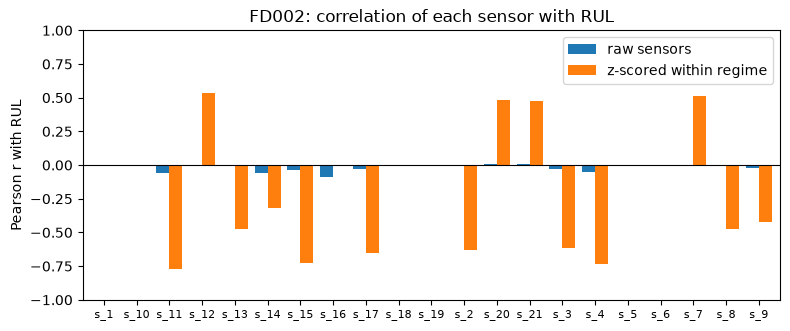

In [11]:
feat2 = pipe2.transform(train2)                       # z-scored within regime + rolling stats
feat2["rul"] = train2.loc[feat2.index, "rul"].to_numpy()
corr2 = pd.DataFrame({
    "raw sensors": train2[SENSOR_COLS].corrwith(train2["rul"]),
    "z-scored within regime": feat2[pipe2.kept_sensors_].corrwith(feat2["rul"]),
})
fig = plot_rul_correlation(corr2, "FD002")
save(fig, "eda_fd002_rul_correlation.png")
corr2.dropna().reindex(corr2.iloc[:, 1].abs().sort_values(ascending=False).index).dropna().head(8)

**Interpretation.** Raw FD002 sensors are almost uncorrelated with RUL (|r| < 0.1) because the
condition-induced variance swamps the degradation signal; after z-scoring each sensor inside its
regime the correlations come back to FD001-like magnitudes (|r| ≈ 0.5–0.7 for s_11, s_4, s_12, s_7,
s_15, s_21). Regime normalisation is therefore a prerequisite, not a refinement, for FD002/FD004.

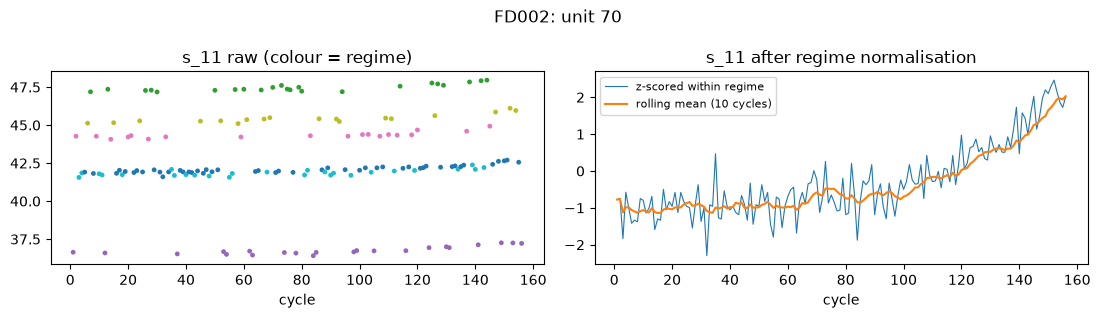

In [12]:
fig = plot_before_after_regime(train2, feat2, unit=int(units2[0]), sensor="s_11", subset="FD002")
save(fig, "eda_fd002_regime_normalisation.png")

**Interpretation.** For a single engine the raw s_11 trace is six interleaved bands (one per regime);
after within-regime standardisation the bands collapse onto one noisy curve whose 10-cycle rolling
mean rises steadily towards failure — the feature the models will actually see.

## Take-aways for the pipeline (step 3)
- Drop the seven constant sensors; keep 14 (`FeaturePipeline` detects them from the training engines).
- For FD002/FD004: KMeans(6, seed 0) on the standardised settings → z-score every sensor within its regime.
- Add 10-cycle rolling mean and std per engine to average out the sensor noise.
- Cap the label at 125 — the sensors carry no information about RUL above that.